# Real-world evaluation of the plant disease model

The ResNet-9 reached 99.2% validation accuracy on PlantVillage. Here it is scored on 215 real in-field photos from the PlantDoc test split (CC-BY-4.0, see `real_images/SOURCES.md`). Results come from `real_world_eval.py` (run from the repo root) and are loaded from `real_world_results.csv`. They reflect the app's preprocessing **before** the RGB / non-square fixes.

In [1]:
import pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
ROOT = Path('..') if Path('../real_world_results.csv').exists() else Path('.')
df = pd.read_csv(ROOT/'real_world_results.csv')
ok = df[~df.model_crashed].copy()
ok['correct'] = ok.correct.astype(bool); ok['correct_crop'] = ok.correct_crop.astype(bool)
rows=[]
for m,g in ok.groupby('preprocess'):
    w=g[~g.correct]
    rows.append(dict(preprocess=m, images=len(g), crashed=int(df[(df.preprocess==m)].model_crashed.sum()),
        exact=f'{g.correct.mean():.0%}', right_crop=f'{g.correct_crop.mean():.0%}',
        avg_conf_when_wrong=f'{w.confidence.mean():.0%}', wrong_ge90=f'{(w.confidence>=0.9).sum()}/{len(w)}'))
pd.DataFrame(rows).set_index('preprocess')

,images,crashed,exact,right_crop,avg_conf_when_wrong,wrong_ge90
preprocess,,,,,,
app,212,3,13%,31%,76%,67/185
square,215,0,9%,23%,73%,54/195


## Most common confusions (app preprocessing)

In [2]:
app = ok[ok.preprocess=='app']
app[~app.correct].groupby(['true_label','predicted']).size().sort_values(ascending=False).head(10).rename('count').to_frame()

,,count
true_label,predicted,
Tomato___Septoria_leaf_spot,Tomato___Early_blight,7
Potato___Late_blight,Tomato___Late_blight,5
Apple___Cedar_apple_rust,"Pepper,_bell___Bacterial_spot",5
Apple___healthy,"Pepper,_bell___healthy",4
Raspberry___healthy,Blueberry___healthy,4
Soybean___healthy,Blueberry___healthy,3
Tomato___Bacterial_spot,"Pepper,_bell___Bacterial_spot",3
Tomato___Tomato_mosaic_virus,Grape___Esca_(Black_Measles),3
Strawberry___healthy,Blueberry___healthy,3


## Accuracy per true class (app preprocessing)

In [3]:
app.groupby('true_label').correct.agg(['mean','count']).round(2).sort_values('mean')

,mean,count
true_label,,
Apple___Apple_scab,0.00,10
Apple___Cedar_apple_rust,0.00,10
Grape___Black_rot,0.00,8
Cherry_(including_sour)___healthy,0.00,10
Potato___Late_blight,0.00,8
Soybean___healthy,0.00,8
Squash___Powdery_mildew,0.00,6
Potato___Early_blight,0.00,8
Tomato___Leaf_Mold,0.00,6


## What the model predicts most often

In [4]:
app.predicted.value_counts().head(8).to_frame('predictions')

,predictions
predicted,
"Pepper,_bell___Bacterial_spot",36
Tomato___Early_blight,34
Tomato___Late_blight,27
Blueberry___healthy,21
"Pepper,_bell___healthy",14
Apple___Cedar_apple_rust,13
Corn_(maize)___healthy,11
Grape___Esca_(Black_Measles),7


## Example images (app preprocessing)

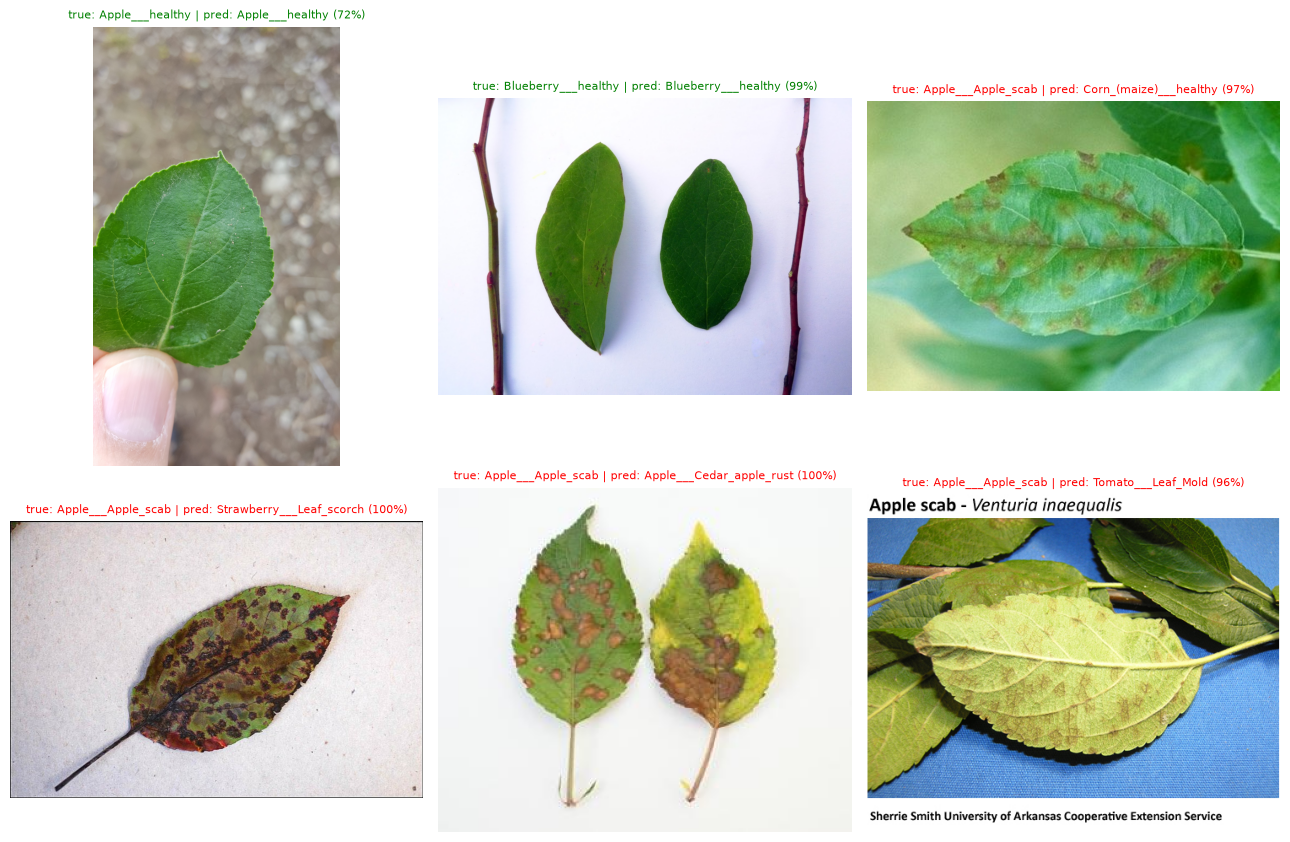

In [5]:
ex = pd.concat([app[app.correct].head(2), app[~app.correct & (app.confidence>=0.9)].head(4)])
fig, axs = plt.subplots(2,3, figsize=(13,9))
for ax,(_,r) in zip(axs.ravel(), ex.iterrows()):
    ax.imshow(Image.open(ROOT/r.image).convert('RGB')); ax.axis('off')
    ax.set_title(f"true: {r.true_label} | pred: {r.predicted} ({r.confidence:.0%})", fontsize=8, color='green' if r.correct else 'red')
plt.tight_layout(); plt.show()

## Conclusion

On real field photos the model picks the exact right label only about 1 time in 8 (13%) with the app's preprocessing, and the right crop about 3 times in 10 (31%). That is far below the 99.2% validation figure, which only measures how well it handles more PlantVillage-style lab photos. When it is wrong it is still usually very sure of itself (average 76% confidence, and many wrong answers above 90%), so the confidence number should not be shown to farmers as a reliability signal.

Likely causes: (1) domain shift from clean lab photos to cluttered field photos, (2) the model leaning on background and colour rather than lesions (it over-predicts a few classes such as Pepper bacterial spot and Tomato early blight), and (3) some label noise in PlantDoc. Not every cause was tested separately.

Caveats: small sample (4-12 images per class), only 25 classes covered, and the app and square preprocessing differ by too little to draw a conclusion. Separately, the original app code crashed on non-RGB and elongated images; both are fixed in `app/app.py` after this evaluation.